# 01 · Exploración de datos (CRISP-DM: Comprensión de los datos)

Dataset: Online Retail II (UCI), transacciones de un retailer en línea del Reino Unido entre 01/12/2009 y 09/12/2011.
Objetivo: entender la estructura y la calidad de los datos antes de limpiarlos y segmentar clientes.

In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/online_retail_II.csv")

print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
df.info()
print()
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [4]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [5]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Rango de fechas:", df["InvoiceDate"].min(), "a", df["InvoiceDate"].max())
print("Clientes únicos:", df["Customer ID"].nunique())
print("Países:", df["Country"].nunique())
print()
print("Facturas canceladas (empiezan con C):", df["Invoice"].str.startswith("C").sum())
print("Filas con Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Filas con Price <= 0:", (df["Price"] <= 0).sum())
print("Filas duplicadas:", df.duplicated().sum())
print()
print("Códigos que no son productos (los que no empiezan con 5 dígitos):")
print(df.loc[~df["StockCode"].str.match(r"^\d{5}"), "StockCode"].value_counts().head(15))

Rango de fechas: 2009-12-01 07:45:00 a 2011-12-09 12:50:00
Clientes únicos: 5942
Países: 43

Facturas canceladas (empiezan con C): 19494
Filas con Quantity <= 0: 22950
Filas con Price <= 0: 6207
Filas duplicadas: 34335

Códigos que no son productos (los que no empiezan con 5 dígitos):
StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
Name: count, dtype: int64


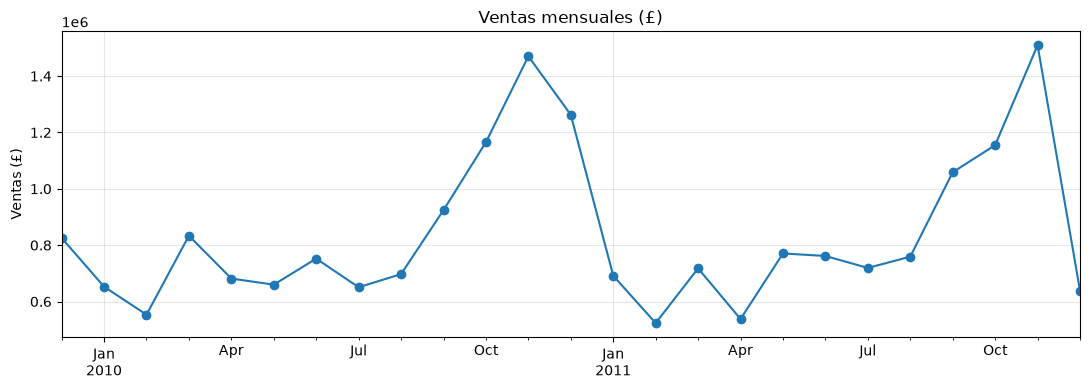

In [6]:
import matplotlib.pyplot as plt

# Filtro temporal solo para explorar (la limpieza formal va en el notebook 02)
ventas = df[
    (~df["Invoice"].str.startswith("C"))
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
].copy()
ventas["Total"] = ventas["Quantity"] * ventas["Price"]

mensual = ventas.set_index("InvoiceDate").resample("ME")["Total"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
mensual.plot(ax=ax, marker="o")
ax.set_title("Ventas mensuales (£)")
ax.set_xlabel("")
ax.set_ylabel("Ventas (£)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figuras/ventas_mensuales.png", dpi=150)
plt.show()

In [7]:
paises = ventas.groupby("Country")["Total"].sum().sort_values(ascending=False)
participacion = (paises / paises.sum() * 100).round(1)
participacion.head(10)

Country
United Kingdom    85.2
EIRE               3.2
Netherlands        2.6
Germany            2.1
France             1.7
Australia          0.8
Spain              0.5
Switzerland        0.5
Sweden             0.4
Denmark            0.3
Name: Total, dtype: float64

## Conclusiones de la exploración

- 1,067,371 filas y 8 columnas; 5,942 clientes de 43 países.
- Los datos originales no se modifican. Para el análisis RFM se excluirán las filas que no representan compras identificables de productos, y se medirá el impacto de cada exclusión:
  - 243,007 filas (≈23 %) sin `Customer ID`: no se pueden asignar a un cliente. Se cuantificará su peso en ventas.
  - 19,494 filas de facturas canceladas (prefijo C) y 22,950 con cantidad ≤ 0: no cuentan como compras, pero se usarán para calcular la tasa de devolución por cliente.
  - 6,207 filas con precio ≤ 0: ajustes, regalos o deudas, no ventas.
  - 34,335 filas duplicadas exactas: se asumen errores de registro (supuesto documentado).
  - Códigos que no son productos (POST, DOT, M, D, S, C2, BANK CHARGES, ADJUST, AMAZONFEE, vales de regalo, PADS): se excluyen para medir solo el gasto en productos.
- Los valores extremos no se eliminan: probablemente son clientes mayoristas. Se tratarán con una transformación logarítmica.
- `InvoiceDate` viene como texto: se convertirá a fecha.
- Las ventas tienen una estacionalidad marcada: suben de septiembre a noviembre (pico ≈ £1.5 M en noviembre) por la campaña navideña.
- El Reino Unido concentra el 85 % de las ventas.